# Telecom Customer Churn Prediction

## Project overview

Customer churn occurs when a customer stops using a company's services. Predicting churn helps a telecom provider identify customers who may leave and understand which customer characteristics are associated with that decision.

This notebook explores the Telco Customer Churn dataset, prepares the data, visualizes customer behavior, trains classification models, and evaluates their predictive performance.

## Project objectives

- Understand the structure and quality of the customer dataset.
- Explore how customer attributes and subscribed services relate to churn.
- Prepare categorical and numerical features for machine-learning algorithms.
- Train and evaluate multiple classification models.
- Compare model behavior using classification metrics and visual evaluation charts.

## Notebook workflow

1. Dataset loading and inspection
2. Data cleaning and preprocessing
3. Exploratory data analysis and customer-level visualizations
4. Feature encoding and correlation analysis
5. Train-test split and numerical feature scaling
6. Classification model training and evaluation
7. Soft-voting ensemble model

## Tools and libraries

- **Pandas and NumPy:** data loading, manipulation, and numerical operations.
- **Matplotlib and Seaborn:** statistical and diagnostic visualizations.
- **Plotly:** interactive charts with hover details and category comparisons.
- **Scikit-learn:** preprocessing, model training, and evaluation.
- **Missingno:** visualization of missing-value patterns.

## Dataset

The notebook expects a CSV file named `Telco_Customer_Churn.csv` at the relative path used in the data-loading cell. The dataset contains customer demographics, account information, subscribed services, billing information, and the `Churn` target column.

## Important interpretation note

The charts describe patterns in the dataset; they do not prove that a feature causes a customer to churn. Model performance should be interpreted using more than accuracy alone, especially when the churn classes are imbalanced.

In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, recall_score, confusion_matrix, precision_score, f1_score, classification_report
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

## 1. Dataset loading

The project uses the Telco Customer Churn dataset. This stage loads the CSV file into a pandas DataFrame, which becomes the working dataset for exploration, preprocessing, visualization, and model training.

In [3]:
df = pd.read_csv("../../../../datasets/Telco_Customer_Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [8]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### Missing-value pattern

This matrix displays where values are present or missing across customer records. Each vertical column represents a feature, and each horizontal row represents a customer. It helps identify columns with incomplete records before preprocessing.

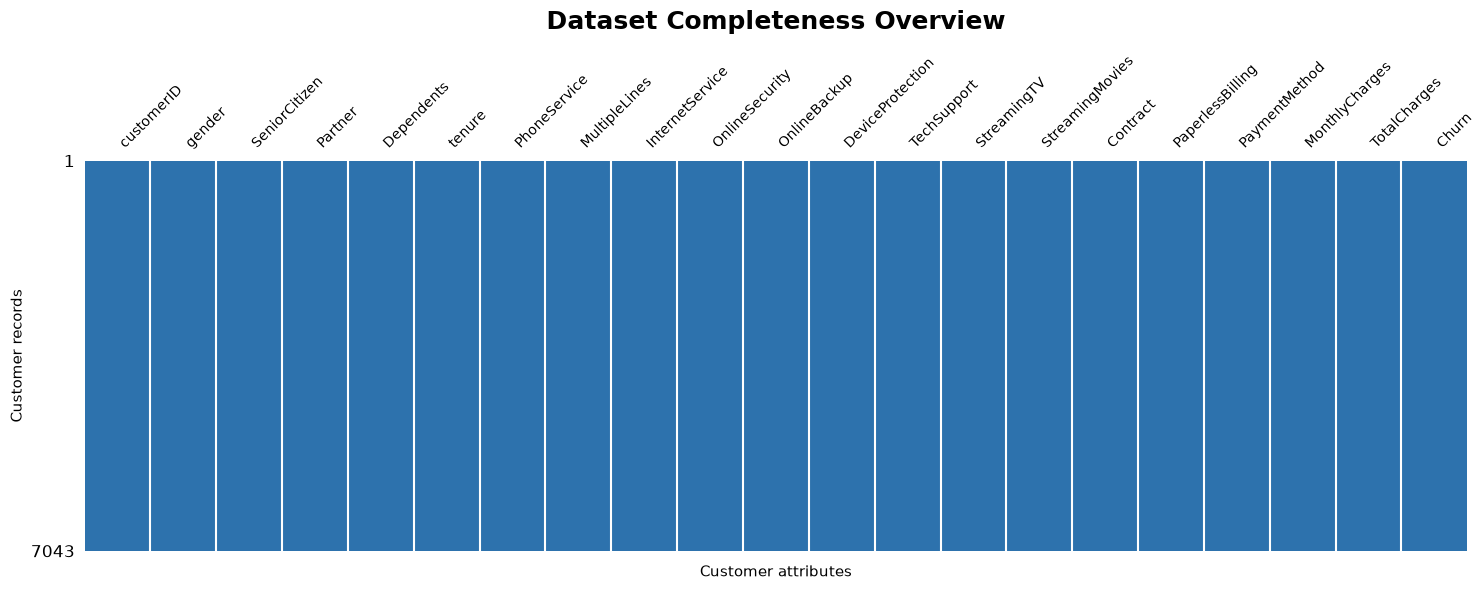

In [9]:
fig, ax = plt.subplots(figsize=(15, 6))
msno.matrix(df, ax=ax, figsize=(15, 6), fontsize=10, sparkline=False, color=(0.18, 0.45, 0.68))
ax.set_title("Dataset Completeness Overview", fontsize=18, fontweight="bold", pad=18)
ax.set_xlabel("Customer attributes", fontsize=11, labelpad=10)
ax.set_ylabel("Customer records", fontsize=11)
plt.tight_layout()
plt.show()

In [10]:
df = df.drop(['customerID'], axis = 1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce')
df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
df[np.isnan(df['TotalCharges'])]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [13]:
df[df['tenure'] == 0].index

Index([488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754], dtype='int64')

In [14]:
df.drop(labels=df[df['tenure'] == 0].index, axis=0, inplace=True)
df[df['tenure'] == 0].index

Index([], dtype='int64')

In [15]:
df.fillna(df['TotalCharges'].mean())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [16]:
df.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [17]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
df["InternetService"].describe(include=['object', 'bool'])

count            7032
unique              3
top       Fiber optic
freq             3096
Name: InternetService, dtype: object

In [19]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[numerical_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


## 2. Exploratory data analysis

Exploratory Data Analysis (EDA) is used to understand the customer population and identify patterns related to churn. The following charts summarize the distribution of gender and the target variable.

### Gender and churn composition

Two doughnut charts compare the distribution of customer gender and churn status. Hover over a segment to inspect its count and percentage.

In [20]:
g_labels = ['Male', 'Female']
c_labels = ['No', 'Yes']

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{'type': 'domain'}, {'type': 'domain'}]],
    subplot_titles=("Customer Gender", "Customer Churn")
)
fig.add_trace(
    go.Pie(
        labels=g_labels,
        values=df['gender'].value_counts(),
        name="Gender",
        hole=0.62,
        marker=dict(colors=["#2563EB", "#F472B6"], line=dict(color="white", width=3)),
        textinfo="label+percent",
        textposition="outside",
        hovertemplate="<b>%{label}</b><br>Customers: %{value:,}<br>Share: %{percent}<extra></extra>"
    ),
    1, 1
)
fig.add_trace(
    go.Pie(
        labels=c_labels,
        values=df['Churn'].value_counts(),
        name="Churn",
        hole=0.62,
        marker=dict(colors=["#16A34A", "#EF4444"], line=dict(color="white", width=3)),
        textinfo="label+percent",
        textposition="outside",
        hovertemplate="<b>%{label}</b><br>Customers: %{value:,}<br>Share: %{percent}<extra></extra>"
    ),
    1, 2
)
fig.update_layout(
    title=dict(text="Customer Profile and Churn Distribution", x=0.5, xanchor="center", font=dict(size=22)),
    template="plotly_white",
    height=560,
    width=1050,
    margin=dict(t=100, b=45, l=55, r=55),
    font=dict(family="Arial", size=13, color="#243247"),
    showlegend=False
)
fig.show()

In [21]:
df["Churn"][df["Churn"] == "No"].groupby(by=df["gender"]).count()

gender
Female    2544
Male      2619
Name: Churn, dtype: int64

In [22]:
df["Churn"][df["Churn"] == "Yes"].groupby(by=df["gender"]).count()

gender
Female    939
Male      930
Name: Churn, dtype: int64

### Nested churn and gender view

The outer ring represents the overall churn categories, while the inner ring shows the gender segments used in the original analysis. The chart gives a compact visual summary of the supplied category counts.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


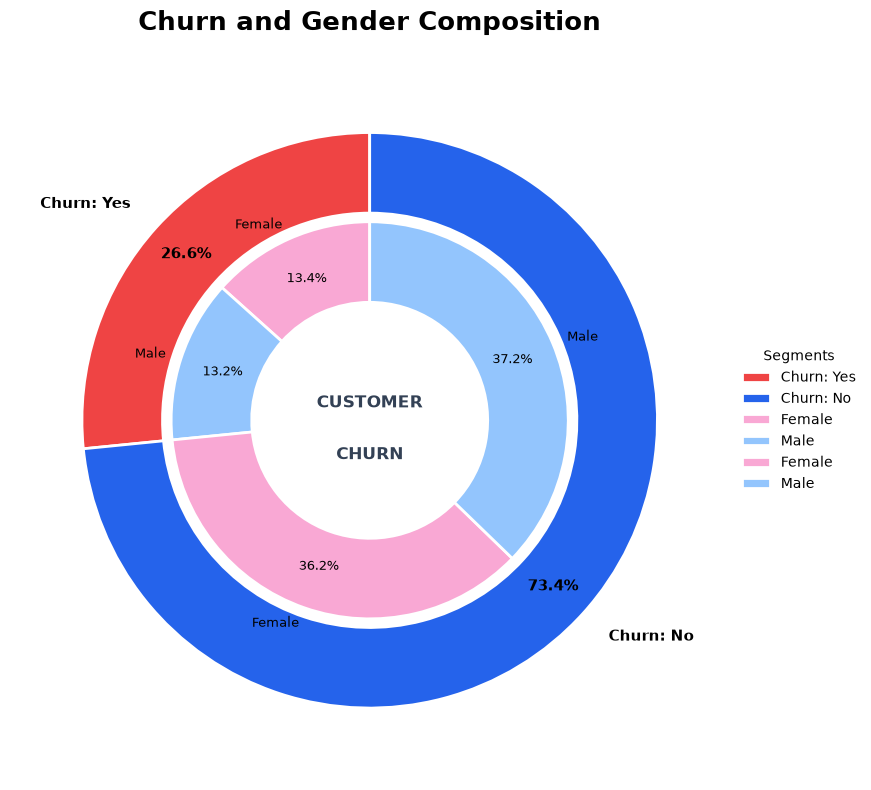

In [23]:
labels = ["Churn: Yes", "Churn: No"]
values = [1869, 5163]
labels_gender = ["Female", "Male", "Female", "Male"]
sizes_gender = [939, 930, 2544, 2619]

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"aspect": "equal"})
outer_colors = ["#EF4444", "#2563EB"]
inner_colors = ["#F9A8D4", "#93C5FD", "#F9A8D4", "#93C5FD"]

outer_wedges, outer_texts, outer_autotexts = ax.pie(
    values,
    radius=1.0,
    labels=labels,
    colors=outer_colors,
    autopct="%1.1f%%",
    pctdistance=0.86,
    labeldistance=1.12,
    startangle=90,
    wedgeprops=dict(width=0.28, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=11, weight="semibold")
)
inner_wedges, inner_texts, inner_autotexts = ax.pie(
    sizes_gender,
    radius=0.69,
    labels=labels_gender,
    colors=inner_colors,
    autopct="%1.1f%%",
    pctdistance=0.78,
    labeldistance=1.08,
    startangle=90,
    wedgeprops=dict(width=0.28, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=9)
)
ax.text(0, 0.06, "CUSTOMER", ha="center", va="center", fontsize=12, weight="bold", color="#334155")
ax.text(0, -0.12, "CHURN", ha="center", va="center", fontsize=12, weight="bold", color="#334155")
ax.set_title("Churn and Gender Composition", fontsize=19, weight="bold", pad=22)
ax.legend(
    outer_wedges + inner_wedges,
    labels + labels_gender,
    title="Segments",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False
)
plt.tight_layout()
plt.show()

### Contract type and churn

Grouped bars compare churn and non-churn customer counts across contract types. This helps inspect whether churn differs between month-to-month, one-year, and two-year contracts.

In [24]:
fig = px.histogram(
    df, x="Churn", color="Contract", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_sequence=["#2563EB", "#F59E0B", "#10B981"],
    text_auto=True,
    title="Customer Churn by Contract Type"
)
fig.update_traces(marker_line_color="white", marker_line_width=1.2,
                  hovertemplate="Churn: %{x}<br>Contract: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(
    template="plotly_white", width=950, height=570,
    title=dict(x=0.5, xanchor="center", font=dict(size=21)),
    xaxis_title="Churn status", yaxis_title="Number of customers",
    legend_title="Contract type", bargap=0.18, bargroupgap=0.06,
    margin=dict(t=90, l=70, r=40, b=65),
    font=dict(family="Arial", size=13, color="#243247")
)
fig.show()

### Payment method composition

This doughnut chart shows how customers are distributed across payment methods. Segment size represents the number of customers using each method.

In [25]:
labels = df["PaymentMethod"].value_counts().index
values = df["PaymentMethod"].value_counts().values

fig = go.Figure(
    go.Pie(
        labels=labels,
        values=values,
        hole=0.58,
        sort=False,
        marker=dict(colors=["#2563EB", "#06B6D4", "#F59E0B", "#8B5CF6"],
                    line=dict(color="white", width=3)),
        textinfo="label+percent",
        textposition="outside",
        hovertemplate="<b>%{label}</b><br>Customers: %{value:,}<br>Share: %{percent}<extra></extra>"
    )
)
fig.update_layout(
    title=dict(text="Customer Payment Method Mix", x=0.5, xanchor="center", font=dict(size=21)),
    template="plotly_white", width=950, height=580,
    showlegend=False, margin=dict(t=90, l=70, r=70, b=50),
    annotations=[dict(text="Payment<br>Methods", x=0.5, y=0.5, showarrow=False,
                      font=dict(size=16, weight="bold", color="#334155"))]
)
fig.show()

### Payment method versus churn

Grouped bars compare churn status across payment methods. Use the legend and hover details to inspect the customer counts for each payment category.

In [26]:
fig = px.histogram(
    df, x="Churn", color="PaymentMethod", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_sequence=["#2563EB", "#F59E0B", "#10B981", "#A855F7"],
    text_auto=True,
    title="Churn Distribution Across Payment Methods"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Payment method: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(
    template="plotly_white", width=1000, height=590,
    title=dict(x=0.5, xanchor="center", font=dict(size=21)),
    xaxis_title="Churn status", yaxis_title="Number of customers",
    legend_title="Payment method", bargap=0.18,
    margin=dict(t=90, l=70, r=40, b=65)
)
fig.show()

In [27]:
df["InternetService"].unique()

<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

In [28]:
df[df["gender"] == "Male"][["InternetService", "Churn"]].value_counts()

InternetService  Churn
DSL              No       992
Fiber optic      No       910
No               No       717
Fiber optic      Yes      633
DSL              Yes      240
No               Yes       57
Name: count, dtype: int64

In [29]:
df[df["gender"] == "Female"][["InternetService", "Churn"]].value_counts()

InternetService  Churn
DSL              No       965
Fiber optic      No       889
No               No       690
Fiber optic      Yes      664
DSL              Yes      219
No               Yes       56
Name: count, dtype: int64

### Internet service, gender, and churn

The grouped chart compares the original category counts for DSL, fiber optic, and no-internet customers across gender and churn groups. It provides a multi-category view of the relationship.

In [30]:
fig = go.Figure()

internet_colors = {"DSL": "#2563EB", "Fiber optic": "#F59E0B", "No Internet": "#10B981"}
internet_values = {
    "DSL": [965, 992, 219, 240],
    "Fiber optic": [889, 910, 664, 633],
    "No Internet": [690, 717, 56, 57]
}
category_x = [
    ["Churn: No", "Churn: No", "Churn: Yes", "Churn: Yes"],
    ["Female", "Male", "Female", "Male"]
]
for service, values in internet_values.items():
    fig.add_trace(go.Bar(
        x=category_x,
        y=values,
        name=service,
        marker=dict(color=internet_colors[service], line=dict(color="white", width=1)),
        text=values,
        textposition="outside",
        hovertemplate="Churn: %{x[0]}<br>Gender: %{x[1]}<br>Customers: %{y:,}<extra></extra>"
    ))

fig.update_layout(
    title=dict(text="Churn by Internet Service and Gender", x=0.5, xanchor="center", font=dict(size=21)),
    template="plotly_white", barmode="group", width=1050, height=620,
    xaxis_title="Churn status and gender", yaxis_title="Number of customers",
    legend_title="Internet service", bargap=0.2, bargroupgap=0.08,
    margin=dict(t=95, l=70, r=45, b=75)
)
fig.show()

### Dependents and churn

This chart compares churn counts for customers with and without dependents. The grouped layout makes the two dependent-status categories easier to compare.

In [31]:
color_map = {"Yes": "#16A34A", "No": "#F97316"}
fig = px.histogram(
    df, x="Churn", color="Dependents", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map, text_auto=True,
    title="Customer Churn by Dependent Status"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Dependents: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Has dependents", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Partner status and churn

This chart compares churn counts for customers who have a partner and customers who do not.

In [32]:
color_map = {"Yes": "#2563EB", "No": "#F59E0B"}
fig = px.histogram(
    df, x="Churn", color="Partner", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map, text_auto=True,
    title="Customer Churn by Partner Status"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Partner: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Has partner", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Senior citizen status and churn

This chart compares churn counts by senior-citizen status and churn outcome.

In [33]:
color_map = {"Yes": "#7C3AED", "No": "#06B6D4"}
fig = px.histogram(
    df, x="Churn", color="SeniorCitizen", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map, text_auto=True,
    title="Customer Churn by Senior Citizen Status"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Senior citizen: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Senior citizen", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Reusable categorical comparison function

A reusable plotting function standardizes the appearance of categorical churn comparisons. It accepts the dataset, the churn-axis field, the grouping field, and a chart title.

In [34]:
def plot_bar_graph(df, x_data, color_data, title_name):
    color_map = {"Yes": "#2563EB", "No": "#F59E0B", "No internet service": "#94A3B8"}
    fig = px.histogram(
        df, x=x_data, color=color_data, barmode="group",
        category_orders={x_data: ["No", "Yes"]},
        color_discrete_map=color_map, text_auto=True, title=title_name
    )
    fig.update_traces(marker_line_color="white", marker_line_width=1,
                      hovertemplate=f"{x_data}: %{{x}}<br>{color_data}: %{{fullData.name}}<br>Customers: %{{y:,}}<extra></extra>")
    fig.update_layout(
        template="plotly_white", width=980, height=570,
        title=dict(x=0.5, xanchor="center", font=dict(size=21)),
        xaxis_title=x_data, yaxis_title="Number of customers",
        legend_title=color_data, bargap=0.2, bargroupgap=0.06,
        margin=dict(t=90, l=70, r=40, b=65)
    )
    fig.show()

In [35]:
plot_bar_graph(df, "Churn", "OnlineSecurity", "Churn distribution w.r.t. Online Security")

In [36]:
df["OnlineSecurity"].nunique()

3

### Online security and churn

This detailed grouped chart compares churn outcomes across online-security categories, including the no-internet-service category. Bar labels show counts, while hover details provide the category values.

In [37]:
color_map = {
    "Yes": "#2563EB",
    "No": "#F97316",
    "No internet service": "#94A3B8"
}

fig = px.histogram(
    df,
    x="Churn",
    color="OnlineSecurity",
    barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map,
    text_auto=True,
    title="Customer Churn by Online Security Subscription"
)
fig.update_traces(
    marker=dict(line=dict(width=1.3, color="white")),
    textfont=dict(size=11, color="#1E293B"),
    hovertemplate="<b>Churn:</b> %{x}<br><b>Online security:</b> %{fullData.name}<br><b>Customers:</b> %{y:,}<extra></extra>"
)
fig.update_layout(
    template="plotly_white",
    title=dict(x=0.5, xanchor="center", font=dict(size=22)),
    xaxis=dict(title="Customer churn status", showgrid=False, categoryorder="array", categoryarray=["No", "Yes"]),
    yaxis=dict(title="Number of customers", showgrid=True, gridcolor="#E2E8F0", zeroline=False),
    legend=dict(title="Online security", orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    plot_bgcolor="#FFFFFF",
    paper_bgcolor="#FFFFFF",
    width=1000,
    height=600,
    bargap=0.18,
    bargroupgap=0.06,
    margin=dict(t=115, b=70, l=75, r=45),
    font=dict(family="Arial", size=13, color="#243247")
)
fig.show()

### Paperless billing and churn

This chart compares churn outcomes for customers with paperless billing enabled and disabled.

In [38]:
color_map = {"Yes": "#2563EB", "No": "#F59E0B"}
fig = px.histogram(
    df, x="Churn", color="PaperlessBilling", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map, text_auto=True,
    title="Customer Churn by Paperless Billing"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Paperless billing: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Paperless billing", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Technical support and churn

This chart compares churn outcomes across technical-support subscription categories.

In [39]:
fig = px.histogram(
    df, x="Churn", color="TechSupport", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_sequence=["#2563EB", "#F59E0B", "#94A3B8"],
    text_auto=True, title="Customer Churn by Technical Support"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Technical support: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Technical support", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Phone service and churn

This chart compares churn outcomes for customers with and without phone service.

In [40]:
color_map = {"Yes": "#16A34A", "No": "#F97316"}
fig = px.histogram(
    df, x="Churn", color="PhoneService", barmode="group",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map=color_map, text_auto=True,
    title="Customer Churn by Phone Service"
)
fig.update_traces(marker_line_color="white", marker_line_width=1,
                  hovertemplate="Churn: %{x}<br>Phone service: %{fullData.name}<br>Customers: %{y:,}<extra></extra>")
fig.update_layout(template="plotly_white", width=950, height=560,
                  title=dict(x=0.5, xanchor="center", font=dict(size=21)),
                  xaxis_title="Churn status", yaxis_title="Number of customers",
                  legend_title="Phone service", bargap=0.2, margin=dict(t=90, b=65))
fig.show()

### Monthly charges distribution

Kernel Density Estimation (KDE) curves compare the distribution of monthly charges for customers who churned and those who stayed. The filled areas help compare the shape and concentration of the two distributions.

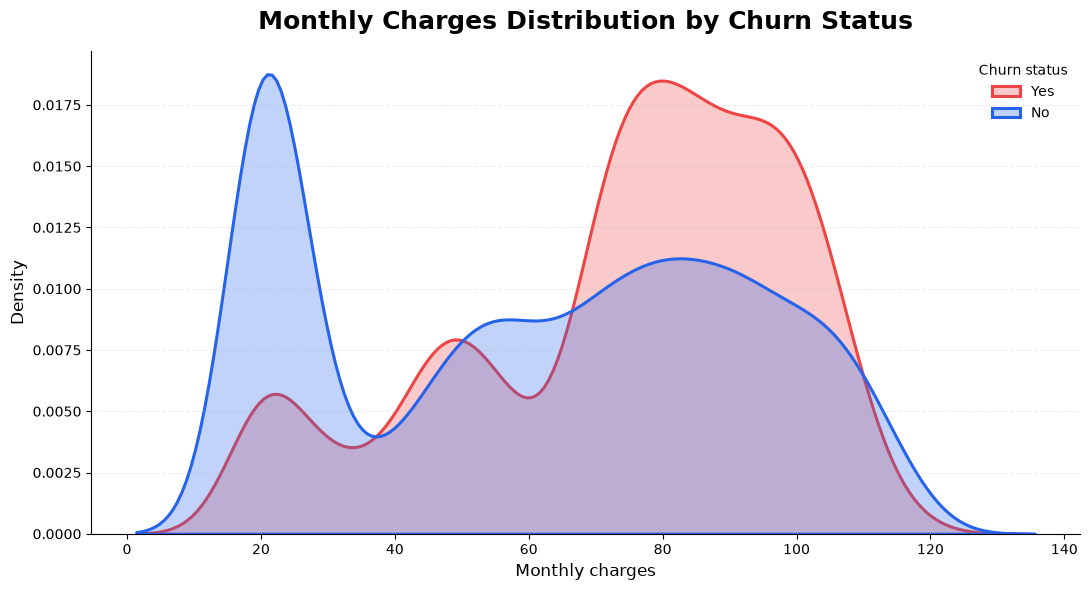

In [41]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.kdeplot(
    data=df, x="MonthlyCharges", hue="Churn",
    fill=True, common_norm=False, alpha=0.28,
    linewidth=2.2, palette={"No": "#2563EB", "Yes": "#EF4444"},
    ax=ax
)
ax.set_title("Monthly Charges Distribution by Churn Status", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Monthly charges", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.grid(axis="y", alpha=0.22, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Churn status", labels=["Yes", "No"], frameon=False)
plt.tight_layout()
plt.show()

### Total charges distribution

This KDE visualization compares total-charge distributions by churn status. It can reveal differences in accumulated charges between customers who left and customers who remained.

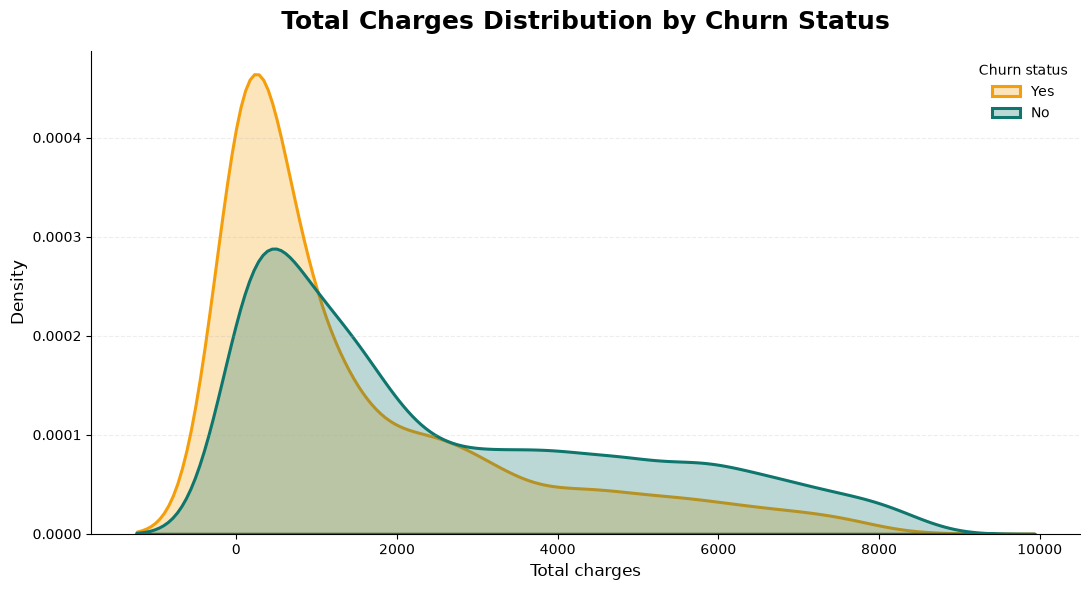

In [42]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.kdeplot(
    data=df, x="TotalCharges", hue="Churn",
    fill=True, common_norm=False, alpha=0.28,
    linewidth=2.2, palette={"No": "#0F766E", "Yes": "#F59E0B"},
    ax=ax
)
ax.set_title("Total Charges Distribution by Churn Status", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Total charges", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.grid(axis="y", alpha=0.22, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Churn status", labels=["Yes", "No"], frameon=False)
plt.tight_layout()
plt.show()

### Tenure distribution by churn

The box plot compares customer tenure in months for the two churn groups. The median, interquartile range, spread, and outliers help show how customer tenure differs by churn status.

In [43]:
fig = px.box(
    df, x="Churn", y="tenure", color="Churn",
    category_orders={"Churn": ["No", "Yes"]},
    color_discrete_map={"No": "#2563EB", "Yes": "#EF4444"},
    points="outliers", notched=True,
    title="Customer Tenure Distribution by Churn Status"
)
fig.update_traces(
    marker=dict(size=4, opacity=0.55),
    line=dict(width=2),
    hovertemplate="Churn: %{x}<br>Tenure: %{y} months<extra></extra>"
)
fig.update_layout(
    template="plotly_white", width=950, height=600,
    title=dict(x=0.5, xanchor="center", font=dict(size=21)),
    xaxis_title="Churn status", yaxis_title="Tenure (months)",
    showlegend=False, margin=dict(t=90, l=70, r=40, b=65)
)
fig.show()

### Feature correlation heatmap

The heatmap visualizes pairwise correlations after the notebook's existing factorization step. Values closer to +1 indicate a stronger positive association, values closer to -1 indicate a stronger negative association, and values near 0 indicate a weaker linear association. Correlation does not establish causation.

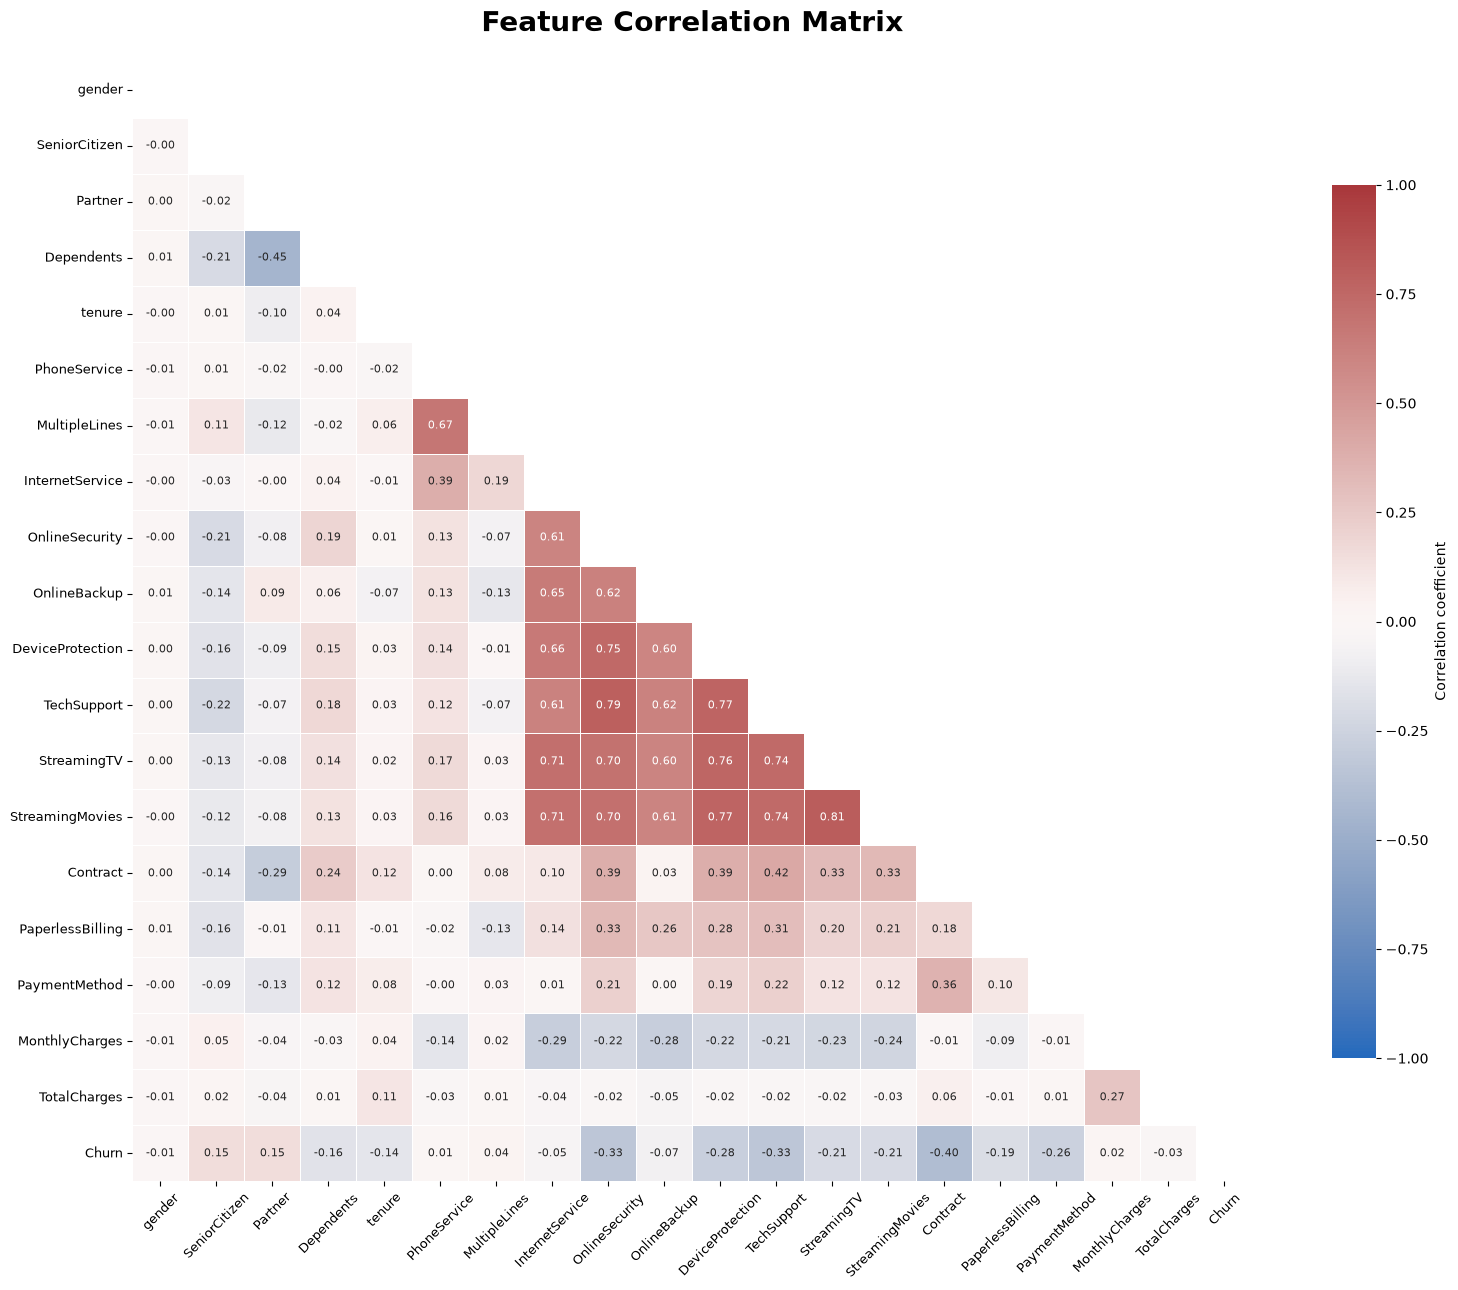

In [44]:
corr = df.apply(lambda x: pd.factorize(x)[0]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(17, 13))
sns.heatmap(
    corr,
    mask=mask,
    xticklabels=corr.columns,
    yticklabels=corr.columns,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.45,
    linecolor="white",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.78, "label": "Correlation coefficient"},
    ax=ax
)
ax.set_title("Feature Correlation Matrix", fontsize=20, weight="bold", pad=22)
ax.tick_params(axis="x", labelrotation=45, labelsize=9)
ax.tick_params(axis="y", labelrotation=0, labelsize=9)
plt.tight_layout()
plt.show()

## 3. Data preparation and feature engineering

This stage converts categorical values into numeric representations so that machine-learning estimators can process them. The existing notebook applies label encoding, binary mapping, and one-hot encoding.

In [45]:
def object_to_int(df_series):
    if df_series.dtype == 'object':
        df_series = LabelEncoder().fit_transform(df_series)
    return df_series

In [46]:
df = df.apply(lambda x: object_to_int(x))
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [47]:
df['gender'] = (df["gender"] == "Male").astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,1,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,1,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,1,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,0,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [48]:
yes_no_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "Churn", "MultipleLines"]

df[yes_no_cols] = (df[yes_no_cols] == "Yes").astype(int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [49]:
categorical_cols = ["InternetService", "Contract", "PaymentMethod"]
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


### Feature relationship with churn

This horizontal bar chart orders the numeric feature correlations with the churn target. Positive and negative bars show the direction of association in the encoded dataset. These values should be interpreted as exploratory signals, not causal effects.

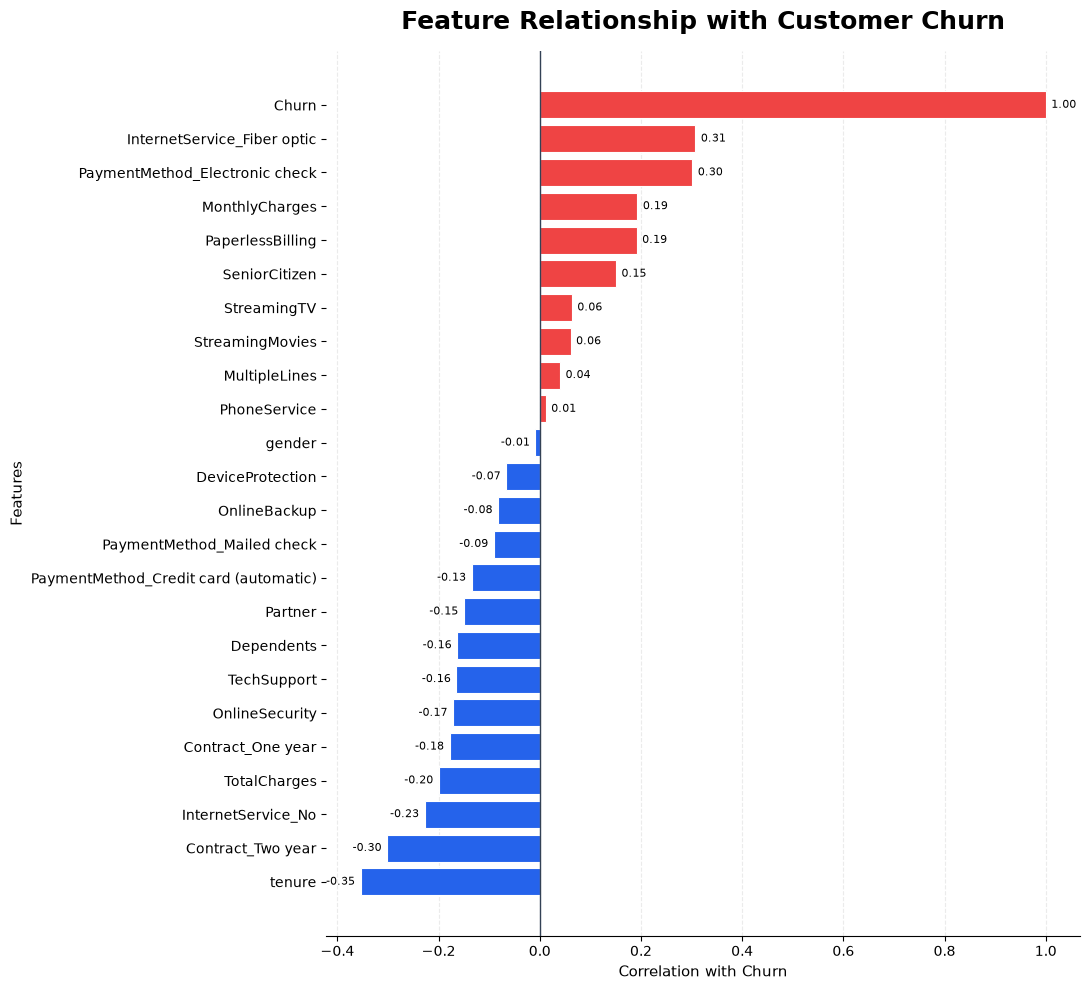

In [50]:
churn_correlation = df.corr(numeric_only=True)["Churn"].sort_values()

fig, ax = plt.subplots(figsize=(11, 10))
bar_colors = ["#EF4444" if value > 0 else "#2563EB" for value in churn_correlation.values]
bars = ax.barh(churn_correlation.index, churn_correlation.values, color=bar_colors, edgecolor="white", linewidth=0.8)
ax.axvline(0, color="#334155", linewidth=1)
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=8)
ax.set_title("Feature Relationship with Customer Churn", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Correlation with Churn", fontsize=11)
ax.set_ylabel("Features", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 4. Feature selection and train-test split

The target column is separated from the predictor features. The dataset is then split into training and testing subsets using the existing stratified split so the churn-class proportion is maintained across the subsets.

In [51]:
X, y = df.drop(columns = ['Churn']), df['Churn'].values

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

## 5. Feature distribution and scaling

The following plots inspect the distributions of numerical features before and after standardization. Histograms show the observed frequency pattern, while the KDE line provides a smoothed view of the distribution.

In [53]:
def distplot(feature, frame, color="#2563EB"):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.histplot(
        data=frame,
        x=feature,
        color=color,
        bins=35,
        kde=True,
        stat="density",
        alpha=0.35,
        edgecolor="white",
        linewidth=0.6,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}", fontsize=17, weight="bold", pad=14)
    ax.set_xlabel(feature, fontsize=11)
    ax.set_ylabel("Density", fontsize=11)
    ax.grid(axis="y", linestyle="--", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

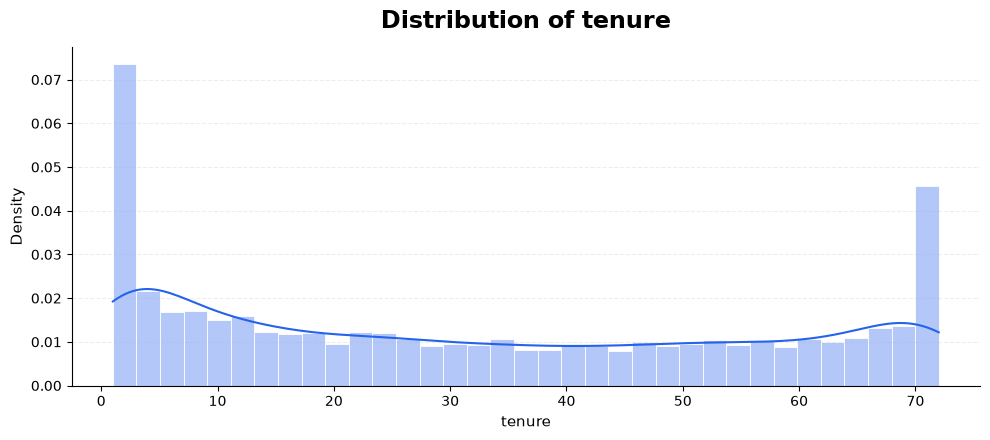

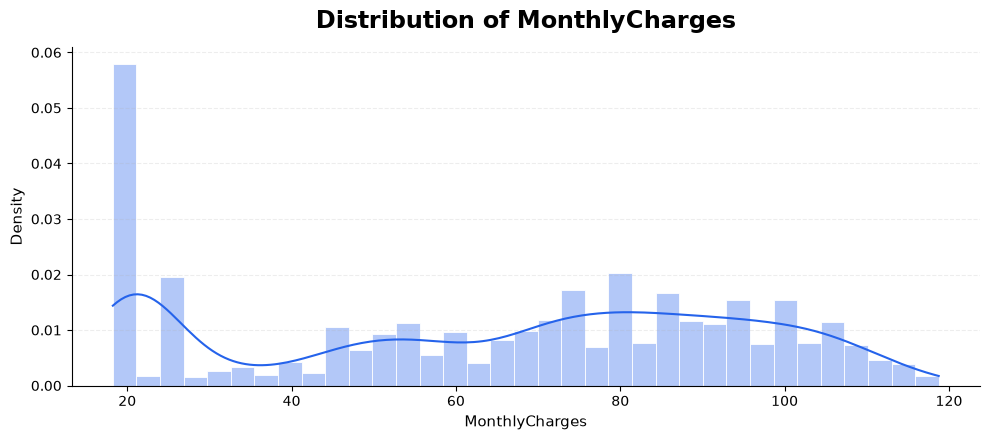

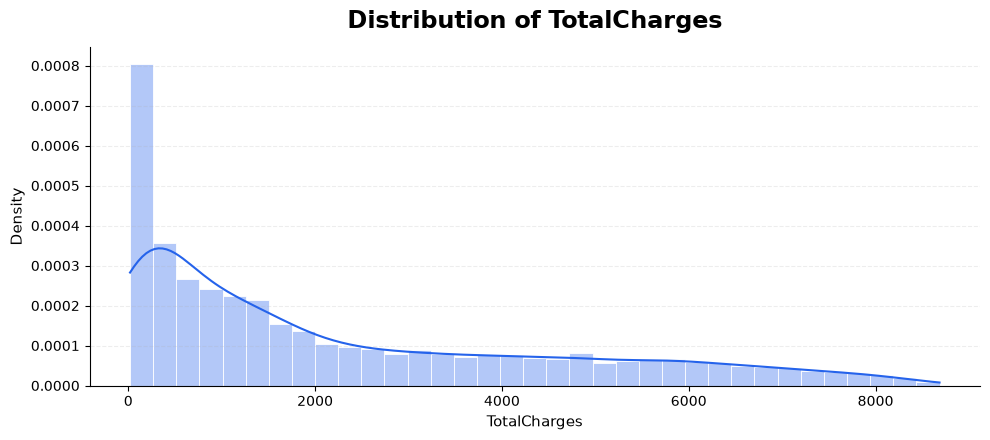

In [54]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for feat in num_cols: distplot(feat, df)

### Standardized numerical feature distributions

These histograms display the numerical columns after the notebook's existing `StandardScaler` transformation. Standardization centers each feature around zero and scales it by its standard deviation. The purpose here is to inspect the transformed distributions, not to modify the model workflow.

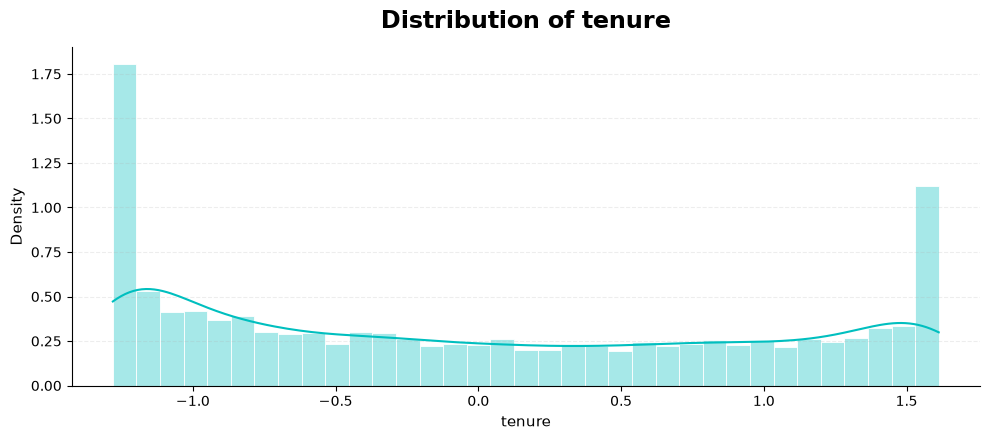

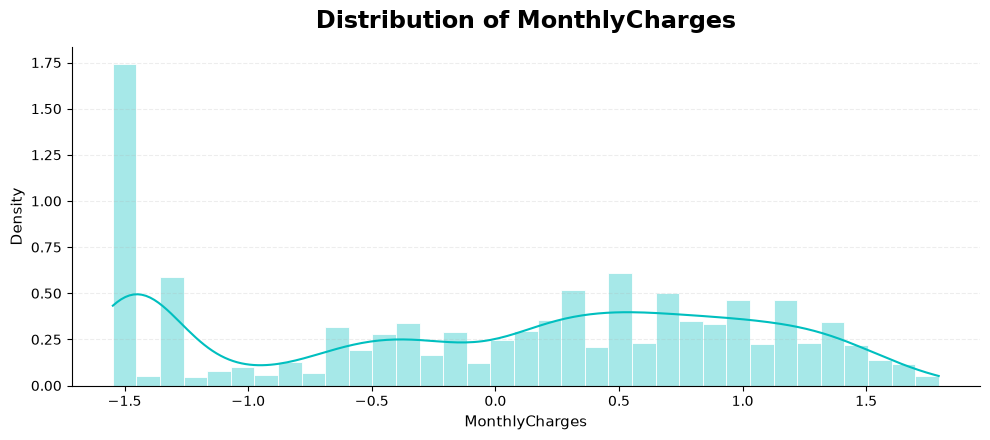

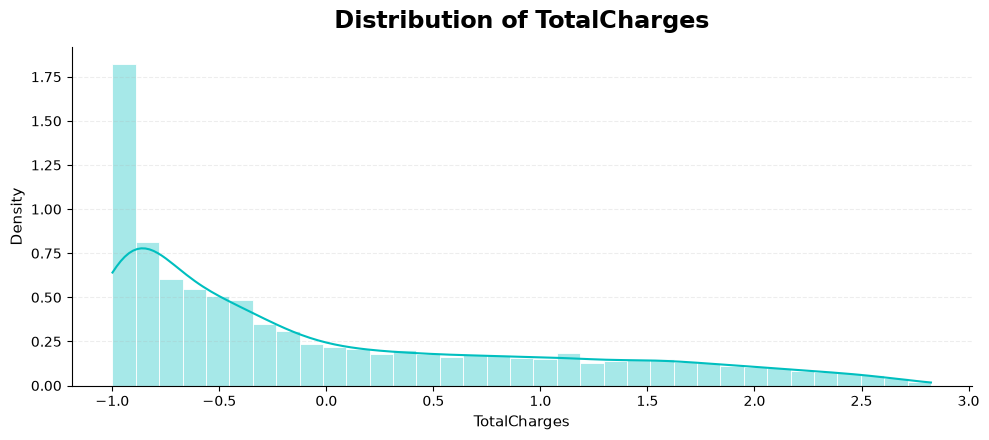

In [55]:
df_std = pd.DataFrame(StandardScaler().fit_transform(df[num_cols].astype('float64')),
                      columns=num_cols)
for feat in numerical_cols: distplot(feat, df_std, color='c')

In [56]:
cat_cols_ohe = ["PaymentMethod", "Contract", "InternetService"]
cat_cols_le = list(set(X_train.columns) - set(num_cols) - set(cat_cols_ohe))

In [57]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## 6. Machine-learning model training and evaluation

The notebook trains several classifiers using the same prepared training and testing data. Evaluation includes accuracy, classification reports, confusion matrices, and ROC curves where probability scores are available.

### K-Nearest Neighbors (KNN)

KNN predicts a customer's class by examining the nearest training examples in feature space. The existing model uses 11 neighbors. Its classification report provides class-wise precision, recall, and F1-score.

In [58]:
knn_model = KNeighborsClassifier(n_neighbors=11)
knn_model.fit(X_train, y_train)
pred_y_knn = knn_model.predict(X_test)
acc_knn = knn_model.score(X_test, y_test)
print("KNN Accuracy: ", acc_knn)

KNN Accuracy:  0.771563981042654


In [59]:
print(classification_report(y_test, pred_y_knn))

              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1549
           1       0.57      0.55      0.56       561

    accuracy                           0.77      2110
   macro avg       0.71      0.70      0.70      2110
weighted avg       0.77      0.77      0.77      2110



### Support Vector Classifier (SVC)

The Support Vector Classifier learns a decision boundary that separates classes. Its accuracy and classification report summarize performance on the held-out test data.

In [60]:
svc_model = SVC(random_state=1)
svc_model.fit(X_train, y_train)
pred_y_svc = svc_model.predict(X_test)
acc_svc = svc_model.score(X_test, y_test)
print("SVC accuracy is: ", acc_svc)

SVC accuracy is:  0.7971563981042654


In [61]:
print(classification_report(y_test, pred_y_svc))

              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1549
           1       0.67      0.47      0.55       561

    accuracy                           0.80      2110
   macro avg       0.75      0.69      0.71      2110
weighted avg       0.78      0.80      0.78      2110



### Random Forest classifier

Random Forest combines predictions from many decision trees. The existing configuration uses 500 trees and the specified out-of-bag and feature-selection settings. The following cells evaluate its predictions and probability ranking.

In [62]:
model_rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
    max_features="sqrt",
    max_leaf_nodes=30
)
model_rf.fit(X_train, y_train)
pred_y_rf = model_rf.predict(X_test)
acc_rf = accuracy_score(y_test, pred_y_rf)
print("Random Forest Classifier: ", acc_rf)

Random Forest Classifier:  0.7914691943127962


In [63]:
print(classification_report(y_test, pred_y_rf))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1549
           1       0.67      0.43      0.52       561

    accuracy                           0.79      2110
   macro avg       0.74      0.68      0.70      2110
weighted avg       0.78      0.79      0.78      2110



### Random Forest confusion matrix

A confusion matrix compares actual labels with predicted labels. The diagonal cells are correct predictions; off-diagonal cells are misclassifications. For churn analysis, pay particular attention to the correctly detected churn customers as well as missed churn cases.

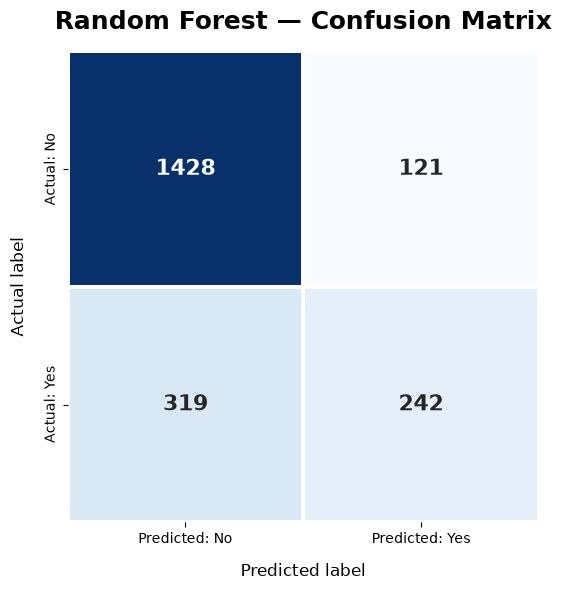

In [64]:
cm_rf = confusion_matrix(y_test, pred_y_rf)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    square=True,
    cbar=False,
    annot_kws={"size": 16, "weight": "bold"},
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"],
    ax=ax
)
ax.set_title("Random Forest — Confusion Matrix", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Predicted label", fontsize=12, labelpad=12)
ax.set_ylabel("Actual label", fontsize=12, labelpad=12)
plt.tight_layout()
plt.show()

### Random Forest ROC curve

The Receiver Operating Characteristic (ROC) curve plots the true-positive rate against the false-positive rate at different classification thresholds. A curve closer to the top-left generally indicates stronger class separation. The dashed diagonal represents random classification.

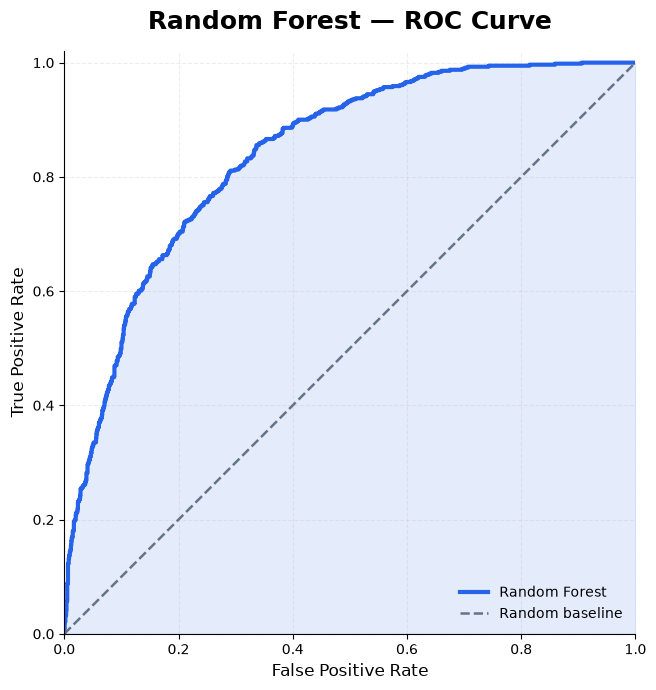

In [65]:
y_rf_pred_prob = model_rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, thresholds = roc_curve(y_test, y_rf_pred_prob)

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(fpr_rf, tpr_rf, color="#2563EB", linewidth=3, label="Random Forest")
ax.plot([0, 1], [0, 1], color="#64748B", linestyle="--", linewidth=1.8, label="Random baseline")
ax.fill_between(fpr_rf, tpr_rf, alpha=0.12, color="#2563EB")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_aspect("equal", adjustable="box")
ax.set_title("Random Forest — ROC Curve", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.grid(alpha=0.22, linestyle="--")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Logistic Regression

Logistic Regression estimates the probability of a class using a linear decision function. It provides a useful baseline for comparing churn classification performance.

In [66]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
accuracy_lr = lr_model.score(X_test, y_test)
print("Logistic Regression Accuracy is: ", accuracy_lr)

Logistic Regression Accuracy is:  0.8042654028436019


In [67]:
lr_pred = lr_model.predict(X_test)
report = classification_report(y_test, lr_pred)
print(report)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1549
           1       0.65      0.56      0.60       561

    accuracy                           0.80      2110
   macro avg       0.75      0.73      0.74      2110
weighted avg       0.80      0.80      0.80      2110



### Logistic Regression confusion matrix

This matrix shows correct and incorrect Logistic Regression predictions for each churn class. Compare the off-diagonal cells to understand which type of error the model makes.

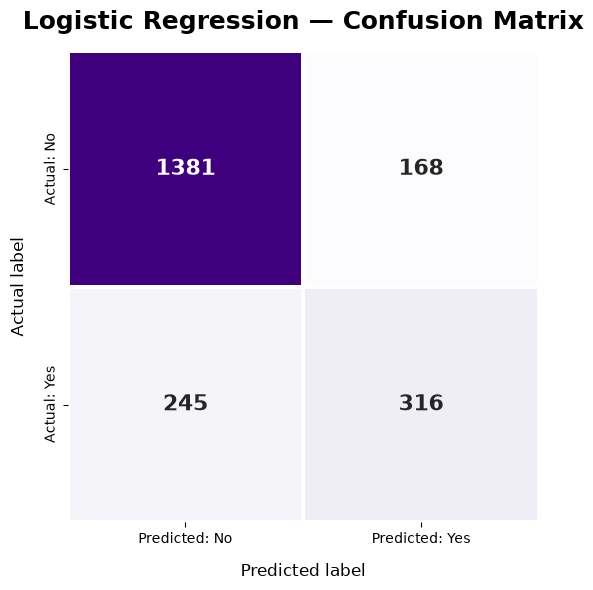

In [68]:
cm_lr = confusion_matrix(y_test, lr_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Purples",
    linewidths=1.5,
    linecolor="white",
    square=True,
    cbar=False,
    annot_kws={"size": 16, "weight": "bold"},
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"],
    ax=ax
)
ax.set_title("Logistic Regression — Confusion Matrix", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Predicted label", fontsize=12, labelpad=12)
ax.set_ylabel("Actual label", fontsize=12, labelpad=12)
plt.tight_layout()
plt.show()

### Logistic Regression ROC curve

This ROC curve shows how Logistic Regression trades off the true-positive rate against the false-positive rate across probability thresholds. The diagonal is the random-baseline reference.

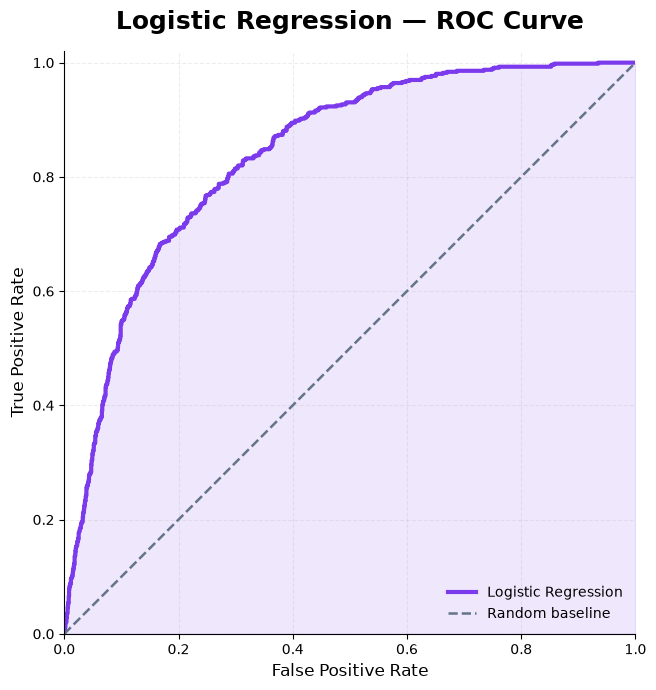

In [69]:
y_pred_prob = lr_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(fpr, tpr, color="#7C3AED", linewidth=3, label="Logistic Regression")
ax.plot([0, 1], [0, 1], color="#64748B", linestyle="--", linewidth=1.8, label="Random baseline")
ax.fill_between(fpr, tpr, alpha=0.12, color="#7C3AED")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_aspect("equal", adjustable="box")
ax.set_title("Logistic Regression — ROC Curve", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.grid(alpha=0.22, linestyle="--")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Decision Tree classifier

A Decision Tree learns a sequence of feature-based splits to classify customers. Its predictions and classification report show how well this single-tree model performs on the test set.

In [70]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
accuracy_dt = dt_model.score(X_test, y_test)
print("Decision Tree accuracy is: ", accuracy_dt)

Decision Tree accuracy is:  0.7118483412322275


In [71]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80      1549
           1       0.46      0.50      0.48       561

    accuracy                           0.71      2110
   macro avg       0.64      0.64      0.64      2110
weighted avg       0.72      0.71      0.72      2110



### AdaBoost classifier

AdaBoost builds an ensemble of weak learners sequentially, giving additional attention to observations that earlier learners classify incorrectly. The notebook evaluates its predictions using accuracy, a classification report, and a confusion matrix.

In [72]:
a_model = AdaBoostClassifier()
a_model.fit(X_train, y_train)
a_preds = a_model.predict(X_test)
accuracy_a = accuracy_score(y_test, a_preds)
print("AdaBoost Classifier Accuracy: ", accuracy_a)

AdaBoost Classifier Accuracy:  0.7928909952606635


In [73]:
print(classification_report(y_test, a_preds))

              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1549
           1       0.66      0.45      0.54       561

    accuracy                           0.79      2110
   macro avg       0.74      0.68      0.70      2110
weighted avg       0.78      0.79      0.78      2110



### AdaBoost confusion matrix

The matrix summarizes AdaBoost predictions against the actual churn labels. The color intensity and annotations make the number of correct and incorrect predictions easier to inspect.

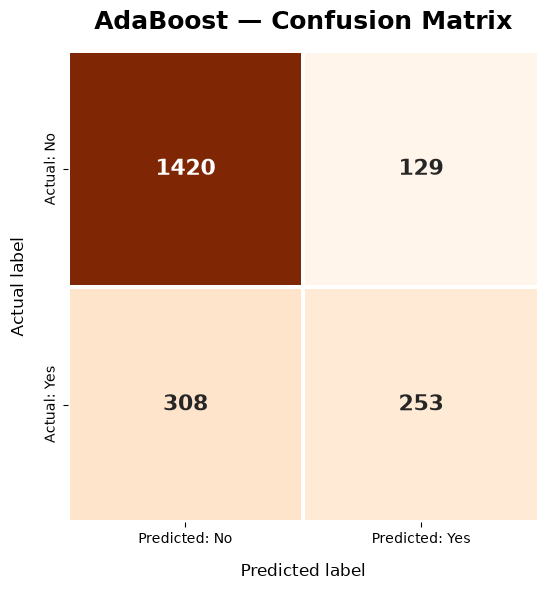

In [74]:
cm_ada = confusion_matrix(y_test, a_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_ada,
    annot=True,
    fmt="d",
    cmap="Oranges",
    linewidths=1.5,
    linecolor="white",
    square=True,
    cbar=False,
    annot_kws={"size": 16, "weight": "bold"},
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"],
    ax=ax
)
ax.set_title("AdaBoost — Confusion Matrix", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Predicted label", fontsize=12, labelpad=12)
ax.set_ylabel("Actual label", fontsize=12, labelpad=12)
plt.tight_layout()
plt.show()

### Gradient Boosting classifier

Gradient Boosting builds an additive ensemble of decision trees, with each stage attempting to improve on the errors of the preceding stages. Its predictions are evaluated in the following cells.

In [75]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
print("Gradient Boosting Classifer accuracy: ", accuracy_score(y_test, gb_pred))

Gradient Boosting Classifer accuracy:  0.7928909952606635


In [76]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1549
           1       0.64      0.50      0.56       561

    accuracy                           0.79      2110
   macro avg       0.74      0.70      0.71      2110
weighted avg       0.78      0.79      0.78      2110



### Gradient Boosting confusion matrix

This matrix summarizes Gradient Boosting predictions against the actual churn labels, using the same interpretation as the other model confusion matrices.

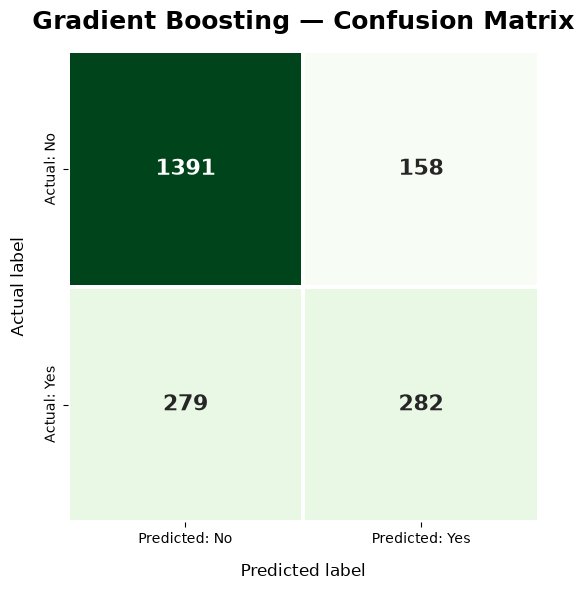

In [77]:
cm_gb = confusion_matrix(y_test, gb_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Greens",
    linewidths=1.5,
    linecolor="white",
    square=True,
    cbar=False,
    annot_kws={"size": 16, "weight": "bold"},
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"],
    ax=ax
)
ax.set_title("Gradient Boosting — Confusion Matrix", fontsize=18, weight="bold", pad=16)
ax.set_xlabel("Predicted label", fontsize=12, labelpad=12)
ax.set_ylabel("Actual label", fontsize=12, labelpad=12)
plt.tight_layout()
plt.show()

## 7. Ensemble learning

The final stage combines Gradient Boosting, Logistic Regression, and AdaBoost in a soft-voting classifier. Soft voting averages class-probability estimates from the component models before producing the final class prediction.

In [78]:
from sklearn.ensemble import VotingClassifier

clf1 = GradientBoostingClassifier()
clf2 = LogisticRegression()
clf3 = AdaBoostClassifier()
eclf1 = VotingClassifier(
    estimators=[
        ('gbc', clf1), ('lr', clf2), ('abc', clf3)
    ],
    voting='soft',
)
eclf1.fit(X_train, y_train)
predictions = eclf1.predict(X_test)
print("Final Accuracy Score ")
print(accuracy_score(y_test, predictions))

Final Accuracy Score 
0.8018957345971564


## 8. Understanding the evaluation results

The notebook reports several complementary evaluation measures:

- **Accuracy:** proportion of all test examples classified correctly.
- **Precision:** among customers predicted as churners, the proportion who actually churned.
- **Recall:** among actual churners, the proportion correctly identified by the model.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** count of true negatives, false positives, false negatives, and true positives.
- **ROC curve:** shows the trade-off between true-positive rate and false-positive rate over classification thresholds.

For a customer-retention use case, recall for the churn class can be especially important because missed churners may represent customers the business could have tried to retain.

## 9. Final ensemble prediction

The soft-voting classifier combines the probability estimates from Gradient Boosting, Logistic Regression, and AdaBoost. Its final accuracy is printed in the last model cell.

## Project outcome

This notebook provides an end-to-end churn-classification workflow: it explores telecom customer data, prepares features, visualizes relationships, trains multiple classifiers, and evaluates an ensemble. The visualizations are intended to make the dataset patterns and model errors easier to interpret.

## Running the notebook

1. Place `Telco_Customer_Churn.csv` at the relative location specified in the loading cell, or update only that file path to match your environment.
2. Install the libraries imported at the beginning of the notebook.
3. Run the notebook from top to bottom so that each preprocessing and model variable is created before it is used.
4. Review the charts together with the classification reports rather than selecting a model from accuracy alone.

The notebook's original preprocessing and model-training code has been retained; the modifications are focused on chart presentation and Markdown documentation.